Relative Strength Index (RSI) er en teknisk momentumindikator som måler styrken i de siste kursbevegelsene til et verdipapir. Den ble utviklet av J. Welles Wilder i 1978 og beregnes ut fra forholdet mellom gjennomsnittlig oppgang og gjennomsnittlig nedgang over en gitt periode, vanligvis 14 dager. Resultatet er et indekstall mellom 0 og 100 uten måleenhet. En RSI over 70 tolkes som at verdipapiret er overkjøpt og kan stå foran en korreksjon ned, mens en RSI under 30 tolkes som at det er oversolgt og kan stå foran en rekyl opp. Indikatoren bygger kun på historiske kurser og kan gi for tidlige signaler i sterke trender, så den bør brukes sammen med andre analyseverktøy.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

[*********************100%***********************]  1 of 1 completed


Price            Close        High         Low        Open   Volume
Ticker          ORK.OL      ORK.OL      ORK.OL      ORK.OL   ORK.OL
Date                                                               
2020-01-02   62.302555   62.482622   61.568445   61.609997   797789
2020-01-03   62.122486   62.261001   61.609994   62.261001   839410
2020-01-06   61.734653   62.011678   61.332968   61.928569  1147350
2020-01-07   62.247147   62.524171   61.900867   61.970127  1387050
2020-01-08   60.751225   61.706953   60.709673   61.540741  1528284
...                ...         ...         ...         ...      ...
2025-12-19  107.036682  107.606537  106.086933  106.181914  2986764
2025-12-22  105.991959  106.941707  105.896985  106.561806  1184245
2025-12-23  106.371857  107.036678  105.991956  105.991956  1099347
2025-12-29  106.941711  107.321612  106.371864  106.656791   984208
2025-12-30  106.846733  107.511554  106.751760  107.036680  1432495

[1508 rows x 5 columns]


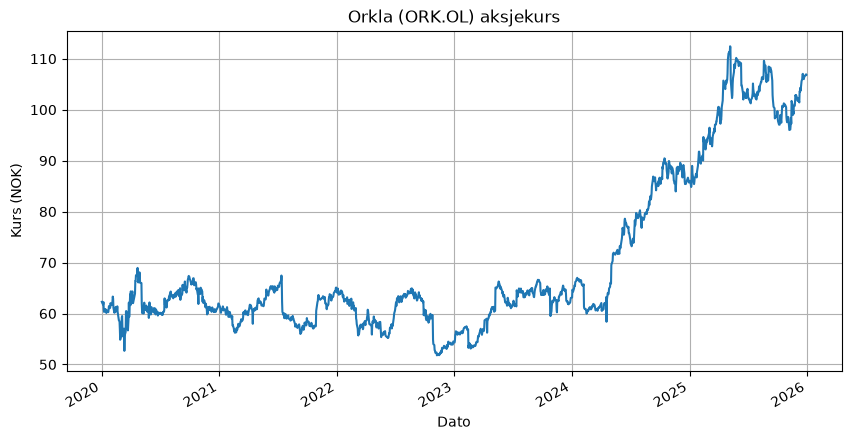

In [2]:
data = yf.download("ORK.OL", start="2020-01-01", end="2026-01-01")
print(data)

data["Close"].plot(figsize=(10, 5), legend=False)
plt.title("Orkla (ORK.OL) aksjekurs")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.grid(True)
plt.show()

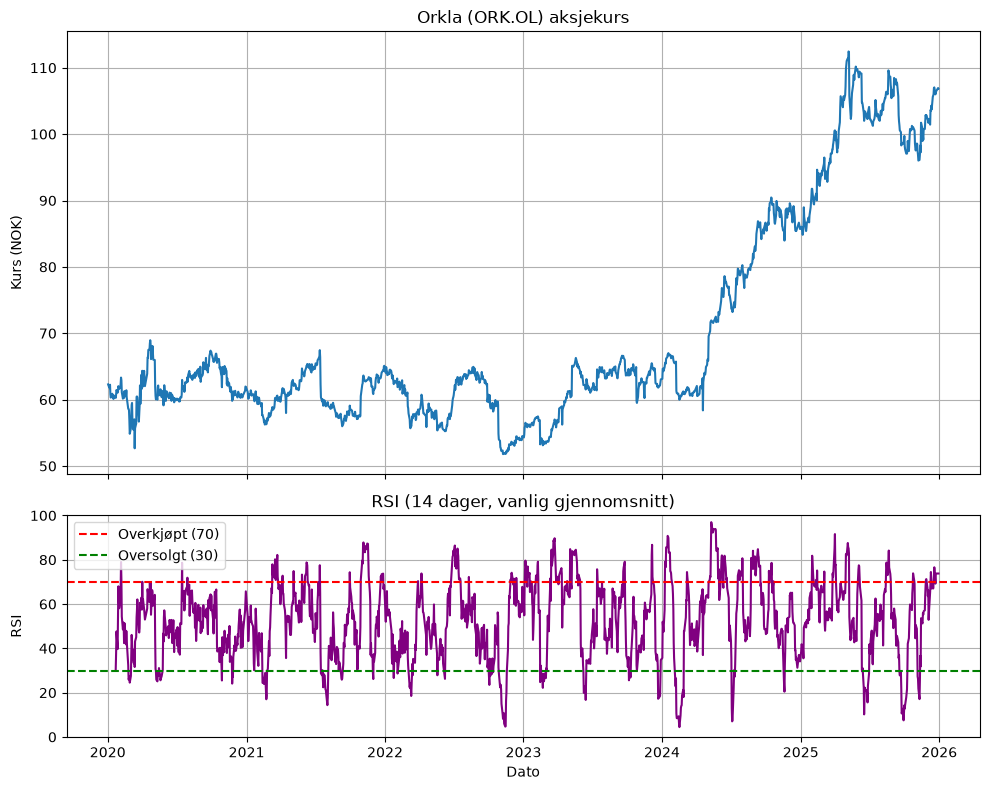

In [14]:
periode = 14

# Sluttkurs som én serie (yfinance gir en tabell med ticker som kolonnenavn)
close = data["Close"].squeeze()

# Daglig endring, delt i oppgang og nedgang
endring = close.diff()
oppgang = endring.clip(lower=0)
nedgang = -endring.clip(upper=0)

# Vanlig gjennomsnitt av de 14 siste dagene
snitt_opp = oppgang.rolling(periode).mean()
snitt_ned = nedgang.rolling(periode).mean()

# RSI
rs = snitt_opp / snitt_ned
rsi = 100 - 100 / (1 + rs)

# Plott kurs og RSI under hverandre
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(close)
ax1.set_title("Orkla (ORK.OL) aksjekurs")
ax1.set_ylabel("Kurs (NOK)")
ax1.grid(True)

ax2.plot(rsi, color="purple")
ax2.axhline(70, color="red", linestyle="--", label="Overkjøpt (70)")
ax2.axhline(30, color="green", linestyle="--", label="Oversolgt (30)")
ax2.set_title(f"RSI ({periode} dager, vanlig gjennomsnitt)")
ax2.set_ylabel("RSI")
ax2.set_xlabel("Dato")
ax2.set_ylim(0, 100)
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

Ovenfor blir RSI verdien for hver 14 dags glidende gjennomsnitt, og stemmer ganske godt med Teorien av RSI. Altså hvis RSI verdien er over 70 er den overkjøpt og vil ofte få en drastisk stigning ned, mens hvis den er under 30 er den oversolgt og vil derfor ofte spike oppover.

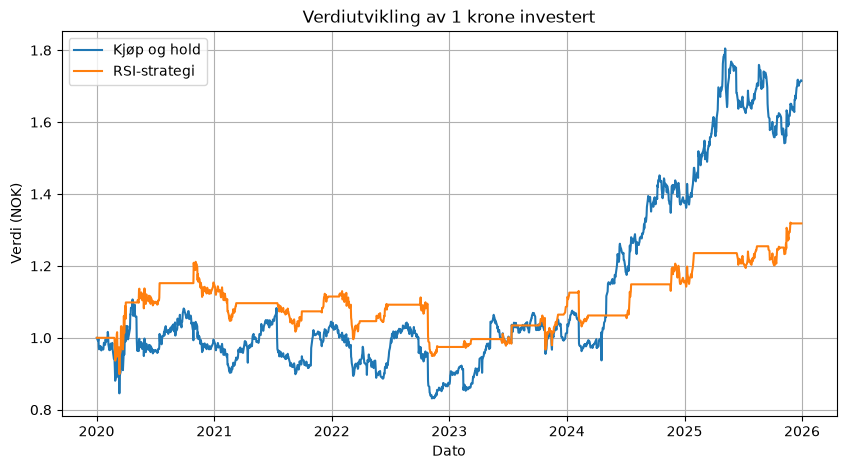

Kjøp og hold:  71.5 % avkastning
RSI-strategi:  31.8 % avkastning
Andel av tiden i markedet: 40.4 %


In [17]:
# Signal: 1 = eier aksjen, 0 = står utenfor
signal = pd.Series(float("nan"), index=rsi.index)
signal[rsi < 30] = 1      # kjøp når oversolgt
signal[rsi > 70] = 0      # selg når overkjøpt
posisjon = signal.ffill().fillna(0)

# Handler dagen etter signalet, så vi ikke bruker informasjon vi ikke har
posisjon = posisjon.shift(1).fillna(0)

# Daglig avkastning
avkastning = close.pct_change().fillna(0)
strategi_avk = posisjon * avkastning

# Verdiutvikling av 1 krone investert
kjop_hold = (1 + avkastning).cumprod()
rsi_strategi = (1 + strategi_avk).cumprod()

# Plott
plt.figure(figsize=(10, 5))
plt.plot(kjop_hold, label="Kjøp og hold")
plt.plot(rsi_strategi, label="RSI-strategi")
plt.title("Verdiutvikling av 1 krone investert")
plt.xlabel("Dato")
plt.ylabel("Verdi (NOK)")
plt.legend(loc="upper left")
plt.grid(True)
plt.show()

# Oppsummering
print(f"Kjøp og hold:  {(kjop_hold.iloc[-1] - 1) * 100:.1f} % avkastning")
print(f"RSI-strategi:  {(rsi_strategi.iloc[-1] - 1) * 100:.1f} % avkastning")
print(f"Andel av tiden i markedet: {posisjon.mean() * 100:.1f} %")

I perioden 2020–2025 ga kjøp og hold en avkastning på 71,5 %, mens RSI-strategien ga 51,1 %, selv om den bare var investert 50,5 % av tiden. Grafen viser at RSI-strategien faktisk lå foran i store deler av perioden, fra rundt midten av 2021 til slutten av 2024. Fra 2020 til våren 2024 beveget Orkla-kursen seg stort sett sidelengs, og da fungerte strategien godt: den kjøpte etter kursfall, solgte etter oppganger og sto utenfor i flere av nedturene, blant annet i 2022. Forskjellen oppsto etter kurshoppet våren 2024. Da gikk RSI over 70 og strategien solgte, og den sto deretter utenfor markedet i over ett år mens kursen fortsatte å stige kraftig. Kjøp og hold fikk med seg hele denne oppgangen og gikk forbi. Resultatet illustrerer den viktigste svakheten ved RSI: den gir gode signaler når kursen svinger rundt et stabilt nivå, men selger for tidlig i en sterk trend. Sammenlikningen ser dessuten bort fra kurtasje og skatt og gjelder bare én aksje i én periode, så den gir ikke grunnlag for å si at kjøp og hold generelt er bedre enn RSI.